In [28]:
import pandas as pd
import numpy as np
import umap
import glob
import os
import joblib
from pathlib import Path

In [29]:
SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output/UMAP/ODE_embeddings"))
REDDIR = Path(os.path.expanduser("~/ECM_mod_output/UMAP"))
if not os.path.exists(SAVEDIR):
    os.mkdir(SAVEDIR)

In [44]:
#if you have a lot of data for umaps

file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\ODE_runs\\exp_conditions\\exp_conditions\\', '*.csv')
filenames = glob.glob(file_location)




#Important params to set the window size and step time distance
init_dt = 0.01                #initial dt from the raw model output
dt = 0.02                      #dt for umap window
window = 2                    #window size in hours
time_step = 0.1   

In [57]:
filenames

['C:\\Users\\olesk\\ECM_mod_output\\ODE_runs\\exp_conditions\\exp_conditions\\ode_cond_1_30_20_40.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_runs\\exp_conditions\\exp_conditions\\ode_cond_1_60_100_40.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_runs\\exp_conditions\\exp_conditions\\ode_cond_2_100_100_60.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_runs\\exp_conditions\\exp_conditions\\ode_cond_2_60_20_60.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_runs\\exp_conditions\\exp_conditions\\ode_cond_3_100_100_100.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_runs\\exp_conditions\\exp_conditions\\ode_cond_3_60_20_100.csv']

In [5]:
#Load umap reducer object
reducer = joblib.load(str(REDDIR) + f'\\reducer_09_04_{init_dt}_{dt}_{window}_{time_step}.sav')

In [58]:
time = np.arange(0,1000.01,0.01)
time_tmp = pd.DataFrame(data=time)

#time_tmp = time_tmp.T
time_tmp.columns = ["time"]
time_tmp2 = time_tmp.iloc[::int(dt//init_dt)].reset_index().drop(columns=['index'])

In [59]:
time_tmp2

,time
0,0.00
1,0.02
2,0.04
3,0.06
4,0.08
...,...
49996,999.92
49997,999.94
49998,999.96
49999,999.98


In [46]:
#create window and total protein arrays
win_len = int(window/dt)
all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
all_time_tmp = np.empty((0,win_len))
all_time_at_tmp = np.empty((0,1))
range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))

for f in filenames:
    prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,18))
    prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", 
    "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
    "cycB", "cycB-p21", "cdc20"]
    prot_tmp2 = prot_tmp.iloc[::int(dt//init_dt),:].reset_index().drop(columns=['index'])
    
    prot_re_tmp = np.empty((len(range_ind),win_len*18))
    time_re_tmp = np.empty((len(range_ind),win_len))
    time_at_tmp = np.empty((len(range_ind),1))

    ii=0
    for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
        tmp = prot_tmp2.iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp=tmp.to_numpy()
        tmp=np.reshape(np.transpose(tmp),win_len*18)
        tmp_at = time_tmp2['time'].iloc[n]
        
        prot_re_tmp[ii,:] = np.array([tmp])
        time_re_tmp[ii,:] = np.array([tmp_t])
        time_at_tmp[ii,:] = np.array([[tmp_at]])
        ii+=1
        
    all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
    all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
    all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
    
    embedding_tmp = reducer.transform(all_prot_tmp)
    split_s = f.split('.')
    split_ss = split_s[0].split('\\')
    name = 'embedding_'+split_ss[-1]+'.csv'
    np.savetxt(str(SAVEDIR) + f'\\{name}', embedding_tmp, delimiter=',', fmt='%f')

In [48]:
embedding_prot_dmso_1 = pd.read_csv("C:\\Users\\olesk\\ECM_mod_output\\UMAP\\ODE_embeddings\\embedding_ode_cond_1_60_100_40.csv", sep=",", header=None)
embedding_prot_dmso_2 = pd.read_csv("C:\\Users\\olesk\\ECM_mod_output\\UMAP\\ODE_embeddings\\embedding_ode_cond_2_100_100_60.csv", sep=",", header=None)
embedding_prot_dmso_3 = pd.read_csv("C:\\Users\\olesk\\ECM_mod_output\\UMAP\\ODE_embeddings\\embedding_ode_cond_3_100_100_100.csv", sep=",", header=None)

embedding_prot_erl_1 = pd.read_csv("C:\\Users\\olesk\\ECM_mod_output\\UMAP\\ODE_embeddings\\embedding_ode_cond_1_30_20_40.csv", sep=",", header=None)
embedding_prot_erl_2 = pd.read_csv("C:\\Users\\olesk\\ECM_mod_output\\UMAP\\ODE_embeddings\\embedding_ode_cond_2_60_20_60.csv", sep=",", header=None)
embedding_prot_erl_3 = pd.read_csv("C:\\Users\\olesk\\ECM_mod_output\\UMAP\\ODE_embeddings\\embedding_ode_cond_3_60_20_100.csv", sep=",", header=None)



In [49]:
prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,18))
prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", 
    "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
    "cycB", "cycB-p21", "cdc20"]
prot_tmp2 = prot_tmp.iloc[::int(dt//init_dt),:].reset_index().drop(columns=['index'])

In [27]:
time_tmp2

,time
0,0.0
1,0.2
2,0.4
3,0.6
4,0.8
...,...
4996,999.2
4997,999.4
4998,999.6
4999,999.8


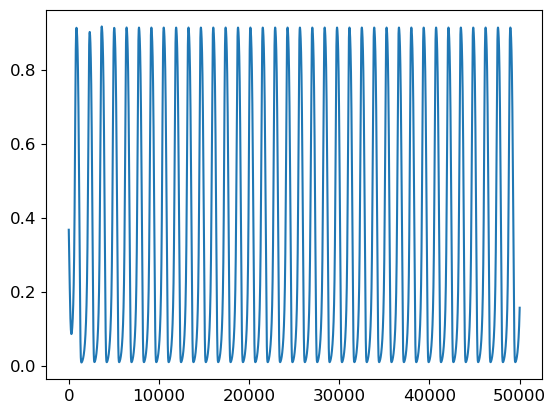

In [60]:
plt.plot(prot_tmp2['cdc20'])

In [50]:
import matplotlib.pyplot as plt
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 14,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

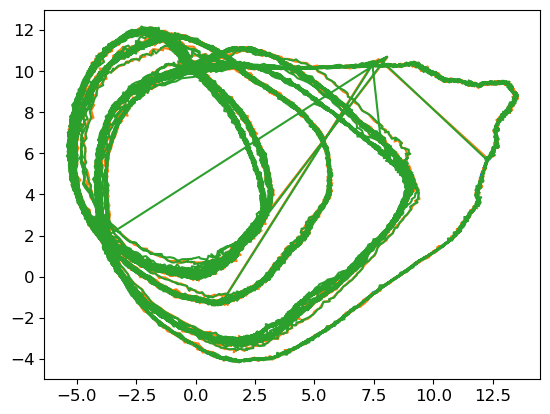

In [56]:
fig = plt.figure()

plt.plot(embedding_prot_erl_1.iloc[3500:,0], embedding_prot_erl_1.iloc[3500:,1])
plt.plot(embedding_prot_erl_2.iloc[3500:,0], embedding_prot_erl_2.iloc[3500:,1])
plt.plot(embedding_prot_erl_3.iloc[3200:,0], embedding_prot_erl_3.iloc[3200:,1])

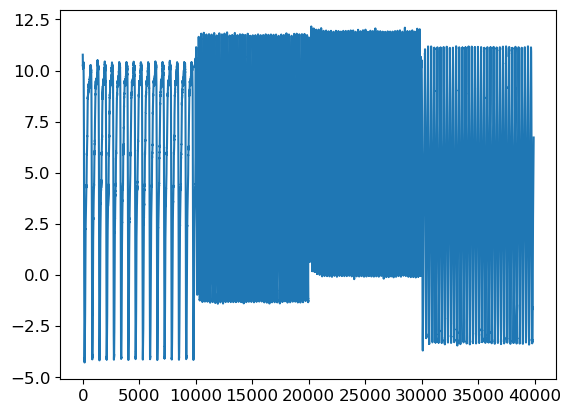

In [62]:
plt.plot(embedding_prot_erl_2.iloc[:,1])